In [ ]:
# Find the project folder and the shared folder paths in scripts/paths.py.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))

from paths import DATA, LOGS, PREDS, SUBMISSIONS

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
TARGET = "12-Month Default Flag"
train = pd.read_csv(DATA / "train_dataset.csv")
test = pd.read_csv(DATA / "test_without_gt.csv")

In [41]:
train.describe()

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
count,6.854600e+04,68546.000000,68546.000000,68546.000000,68546.000000,68546.000000,68546.000000,68546.000000,68546.000000,68546.000000,...,6.854600e+04,68546.000000,6.854600e+04,68546.000000,68546.000000,68546.000000,68546.000000,68546.000000,68546.000000,68546.000000
mean,2.136238e+08,0.096767,16.978234,1.312316,1.311324,415.340501,130.111020,631.528317,34.338152,2.539754,...,3.749241e+05,2.788726,5.375194e+05,1.059887,0.720290,0.428326,0.272868,0.996251,0.967671,0.679806
std,1.017470e+06,0.295643,4.630383,0.463441,0.463038,153.038342,135.567147,324.145195,41.849684,2.014826,...,5.901674e+05,1.542532,7.491039e+06,1.315618,1.301632,0.881467,0.445437,0.061117,0.176873,0.466554
min,2.118500e+08,0.000000,1.000000,1.000000,1.000000,234.000000,0.000000,140.000000,1.000000,1.000000,...,1.000000e+04,1.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.127305e+08,0.000000,17.000000,1.000000,1.000000,282.000000,23.000000,540.000000,5.000000,1.000000,...,1.000000e+05,1.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
50%,2.135701e+08,0.000000,18.000000,1.000000,1.000000,368.000000,77.000000,640.000000,9.000000,1.000000,...,2.000000e+05,4.000000,1.000000e+04,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
75%,2.145100e+08,0.000000,20.000000,2.000000,2.000000,530.000000,214.000000,640.000000,99.000000,5.000000,...,5.000000e+05,4.000000,5.500000e+04,3.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000
max,2.154903e+08,1.000000,20.000000,2.000000,2.000000,840.000000,838.000000,1540.000000,99.000000,8.000000,...,8.000000e+06,6.000000,7.000000e+08,3.000000,20.000000,9.000000,1.000000,1.000000,1.000000,1.000000


In [38]:
test.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,137091.0,2.136221e+08,1.013471e+06,211850001.0,212730539.5,213570461.0,214500044.5,2.154903e+08
Application Channel,137091.0,1.692299e+01,4.708763e+00,1.0,17.0,18.0,20.0,2.000000e+01
Gender,137091.0,1.311435e+00,4.630820e-01,1.0,1.0,1.0,2.0,2.000000e+00
Marital Status,137091.0,1.312318e+00,4.634405e-01,1.0,1.0,1.0,2.0,2.000000e+00
Age (in months),137091.0,4.157294e+02,1.535203e+02,228.0,282.0,369.0,531.0,8.400000e+02
Residence Period (in months),137091.0,1.296439e+02,1.360380e+02,0.0,23.0,77.0,213.0,8.390000e+02
Occupation Category,137091.0,6.307755e+02,3.237777e+02,140.0,540.0,640.0,640.0,1.540000e+03
Industry Category,137091.0,3.421908e+01,4.182208e+01,1.0,5.0,9.0,99.0,9.900000e+01
Employment Type Category,137091.0,2.541400e+00,2.012108e+00,1.0,1.0,1.0,5.0,8.000000e+00
Insurance Type,137091.0,1.733163e+00,1.083587e+00,0.0,1.0,1.0,3.0,4.000000e+00


In [44]:
train.isna().sum()
# test.isna().sum()

ID                                 0
12-Month Default Flag              0
Application Channel                0
Gender                             0
Marital Status                     0
Age (in months)                    0
Residence Period (in months)       0
Occupation Category                0
Industry Category                  0
Employment Type Category           0
Insurance Type                     0
Company Size Category              0
Business Entity Type               0
Declared Annual Income             0
Payday                             0
Declared Number of Borrowings      0
Declared Borrowing Amount          0
Desired Credit Limit               0
Residence Type                     0
Rent Burden                        0
Residence Ownership Status         0
Number of Dependents               0
Number of Dependent Children       0
Home Phone Number Available        0
Mobile Phone Number Available      0
Employer Phone Number Available    0
Driver Licence Number Available    0
d

                                size      mean
Declared Number of Borrowings                 
0                              25340  0.082281
1                              22607  0.093422
2                              12972  0.107693
3                               5463  0.125755
4                               1523  0.145765
5                                456  0.184211
6                                122  0.221311
7                                 40  0.350000
8                                 15  0.200000
9                                  8  0.250000


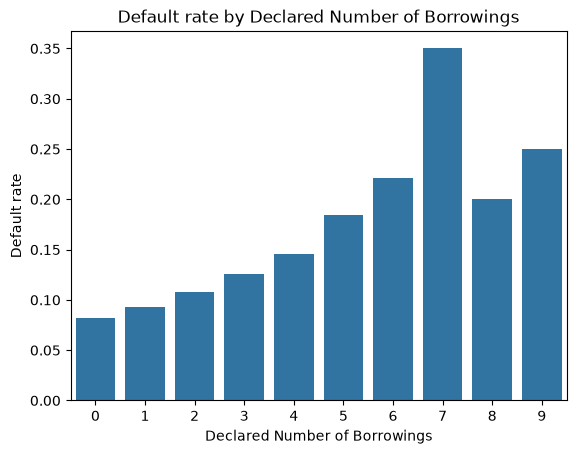

In [32]:
col = "Declared Number of Borrowings"

summary = train.groupby(col)[TARGET].agg(["size", "mean"])
print(summary)

sns.barplot(x=summary.index, y=summary["mean"])
plt.ylabel("Default rate")
plt.title(f"Default rate by {col}")
plt.show()

In [49]:
age_bins = pd.qcut(train["Age (in months)"], 5)
train.groupby(age_bins, observed=True)[TARGET].agg(["size", "mean"])

,size,mean
Age (in months),,
"(233.999, 271.0]",13833,0.121160
"(271.0, 325.0]",13746,0.113342
"(325.0, 426.0]",13595,0.096506
"(426.0, 564.0]",13732,0.079449
"(564.0, 840.0]",13640,0.073021


In [27]:
residence_period_bins = pd.qcut(train["Residence Period (in months)"], 5)
train.groupby(residence_period_bins, observed=True)[TARGET].agg(["size", "mean"])

,size,mean
Residence Period (in months),,
"(-0.001, 18.0]",14159,0.121548
"(18.0, 48.0]",13384,0.107666
"(48.0, 123.0]",13753,0.097870
"(123.0, 243.0]",13660,0.085139
"(243.0, 838.0]",13590,0.070787


In [50]:
annual_income_bins = pd.qcut(train["Declared Annual Income"], 5)
train.groupby(annual_income_bins, observed=True)[TARGET].agg(["size", "mean"])

,size,mean
Declared Annual Income,,
"(-0.001, 2000000.0]",15346,0.086081
"(2000000.0, 2800000.0]",12954,0.105296
"(2800000.0, 3500000.0]",15679,0.104471
"(3500000.0, 4500000.0]",12626,0.099556
"(4500000.0, 94800000000.0]",11941,0.088184


In [47]:
summary = train.groupby("Home Phone Number Available")[TARGET].agg("mean")
print(summary)

Home Phone Number Available
0    0.105975
1    0.072231
Name: 12-Month Default Flag, dtype: float64
